# Solar panels prediction - eda

In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

DATA_RAW_PATH = Path("..") / "data" / "raw_data"

train_raw = pd.read_csv(DATA_RAW_PATH / "train.csv")
train_raw.head()


,Year,Month,Day,Hour,Minute,ClearskyDHI,ClearskyDNI,ClearskyGHI,Cloud Type,Dew Point,Temperature,Pressure,Relative Humidity,Solar Zenith Angle,Precipitable Water,Wind Direction,Wind Speed,Fill Flag
0,2009,1,1,0,0,0,0,0,0,0,5,1010,75.34,106.15,0.499,346.1,3.1,0
1,2009,1,1,0,30,0,0,0,0,1,5,1010,80.81,112.28,0.490,346.1,3.1,0
2,2009,1,1,1,0,0,0,0,4,0,5,1010,78.27,118.50,0.482,347.9,3.2,0
3,2009,1,1,1,30,0,0,0,4,0,4,1010,78.27,124.78,0.478,347.9,3.1,0
4,2009,1,1,2,0,0,0,0,4,0,4,1010,76.45,131.12,0.475,350.0,3.0,0


In [2]:
train_raw.index = pd.to_datetime({'year': train_raw['Year'], 
                                    'Month': train_raw['Month'],
                                    'Day': train_raw['Day'],
                                    'Hour': train_raw['Hour'],
                                    'Minute': train_raw['Minute']})
train_raw.head()

,Year,Month,Day,Hour,Minute,ClearskyDHI,ClearskyDNI,ClearskyGHI,Cloud Type,Dew Point,Temperature,Pressure,Relative Humidity,Solar Zenith Angle,Precipitable Water,Wind Direction,Wind Speed,Fill Flag
2009-01-01 00:00:00,2009,1,1,0,0,0,0,0,0,0,5,1010,75.34,106.15,0.499,346.1,3.1,0
2009-01-01 00:30:00,2009,1,1,0,30,0,0,0,0,1,5,1010,80.81,112.28,0.490,346.1,3.1,0
2009-01-01 01:00:00,2009,1,1,1,0,0,0,0,4,0,5,1010,78.27,118.50,0.482,347.9,3.2,0
2009-01-01 01:30:00,2009,1,1,1,30,0,0,0,4,0,4,1010,78.27,124.78,0.478,347.9,3.1,0
2009-01-01 02:00:00,2009,1,1,2,0,0,0,0,4,0,4,1010,76.45,131.12,0.475,350.0,3.0,0


In [3]:
print(train_raw.info())

<class 'pandas.DataFrame'>
DatetimeIndex: 157776 entries, 2009-01-01 00:00:00 to 2017-12-31 23:30:00
Data columns (total 18 columns):
 #   Column              Non-Null Count   Dtype  
---  ------              --------------   -----  
 0   Year                157776 non-null  int64  
 1   Month               157776 non-null  int64  
 2   Day                 157776 non-null  int64  
 3   Hour                157776 non-null  int64  
 4   Minute              157776 non-null  int64  
 5   ClearskyDHI         157776 non-null  int64  
 6   ClearskyDNI         157776 non-null  int64  
 7   ClearskyGHI         157776 non-null  int64  
 8   Cloud Type          157776 non-null  int64  
 9   Dew Point           157776 non-null  int64  
 10  Temperature         157776 non-null  int64  
 11  Pressure            157776 non-null  int64  
 12  Relative Humidity   157776 non-null  float64
 13  Solar Zenith Angle  157776 non-null  float64
 14  Precipitable Water  157776 non-null  float64
 15  Wind Direct

In [4]:
train_raw = train_raw.drop(['Year', 'Month', 'Day', 'Hour', 'Minute'], axis=1)
train_raw.head()

,ClearskyDHI,ClearskyDNI,ClearskyGHI,Cloud Type,Dew Point,Temperature,Pressure,Relative Humidity,Solar Zenith Angle,Precipitable Water,Wind Direction,Wind Speed,Fill Flag
2009-01-01 00:00:00,0,0,0,0,0,5,1010,75.34,106.15,0.499,346.1,3.1,0
2009-01-01 00:30:00,0,0,0,0,1,5,1010,80.81,112.28,0.490,346.1,3.1,0
2009-01-01 01:00:00,0,0,0,4,0,5,1010,78.27,118.50,0.482,347.9,3.2,0
2009-01-01 01:30:00,0,0,0,4,0,4,1010,78.27,124.78,0.478,347.9,3.1,0
2009-01-01 02:00:00,0,0,0,4,0,4,1010,76.45,131.12,0.475,350.0,3.0,0


In [5]:
print(train_raw.index.is_monotonic_increasing,
      train_raw.index.duplicated().sum())

True 0


In [6]:
train_raw.describe().T

,count,mean,std,min,25%,50%,75%,max
ClearskyDHI,157776.0,53.457313,64.807726,0.000,0.000,0.000,103.0000,565.000
ClearskyDNI,157776.0,328.863167,369.298304,0.000,0.000,0.000,733.0000,1040.000
ClearskyGHI,157776.0,254.206628,327.650151,0.000,0.000,0.000,535.0000,1063.000
Cloud Type,157776.0,2.520054,3.008053,0.000,0.000,1.000,6.0000,10.000
Dew Point,157776.0,13.448281,8.125000,-17.000,8.000,15.000,20.0000,26.000
Temperature,157776.0,18.199365,8.937976,-9.000,12.000,19.000,25.0000,40.000
Pressure,157776.0,1002.692044,5.793128,970.000,1000.000,1000.000,1010.0000,1020.000
Relative Humidity,157776.0,79.432081,19.800666,7.190,65.530,84.390,98.3000,100.000
Solar Zenith Angle,157776.0,89.732548,40.085141,8.550,56.450,89.910,123.0525,171.550
Precipitable Water,157776.0,2.880543,1.538254,0.122,1.526,2.819,4.1770,7.178


In [7]:
train_raw['Pressure'].value_counts()

Pressure
1000    100097
1010     47022
990       8442
1020      2084
980        119
970         12
Name: count, dtype: int64

In [8]:
train_raw['Cloud Type'].value_counts()

Cloud Type
0     73608
7     19637
1     15698
3     14546
8     13457
4     10640
6      6986
2      2880
9       323
10        1
Name: count, dtype: int64

In [9]:
train_raw['Fill Flag'].value_counts()

Fill Flag
0    148705
4      6735
1      2046
3       290
Name: count, dtype: int64

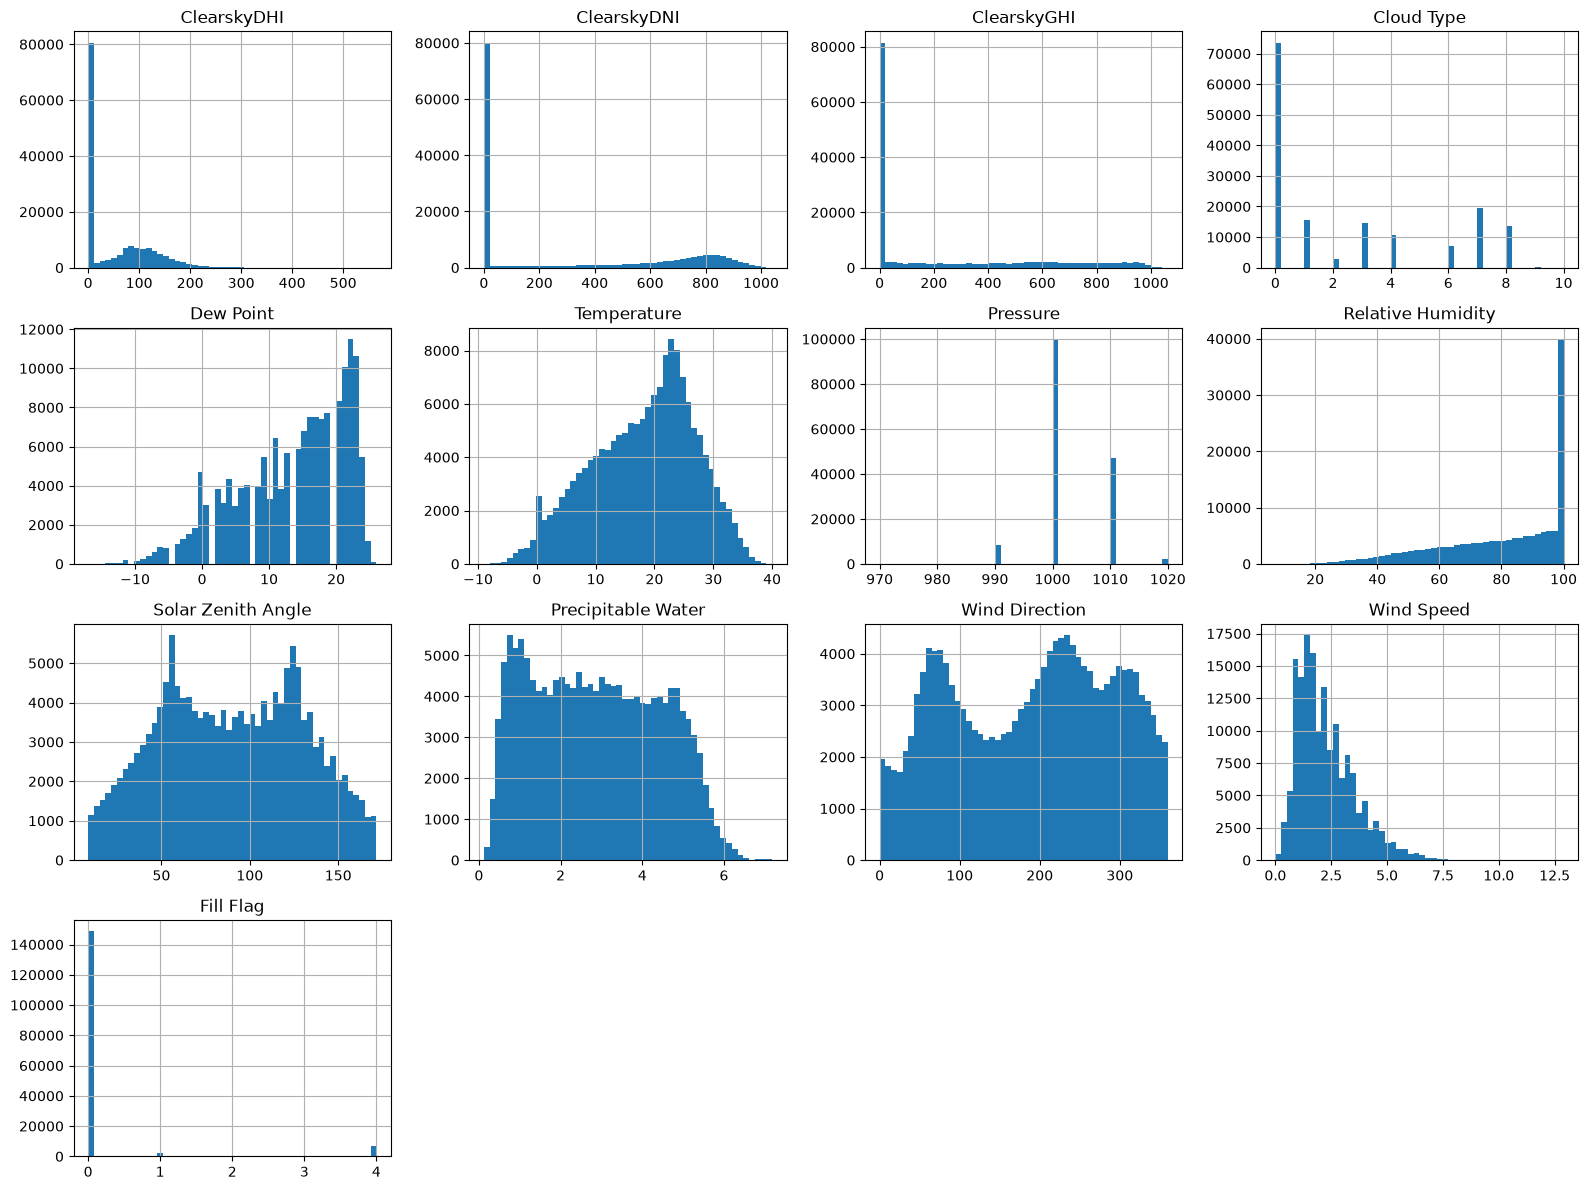

In [10]:
train_raw.hist(figsize=(16,12), bins=50)
plt.tight_layout()
plt.show()

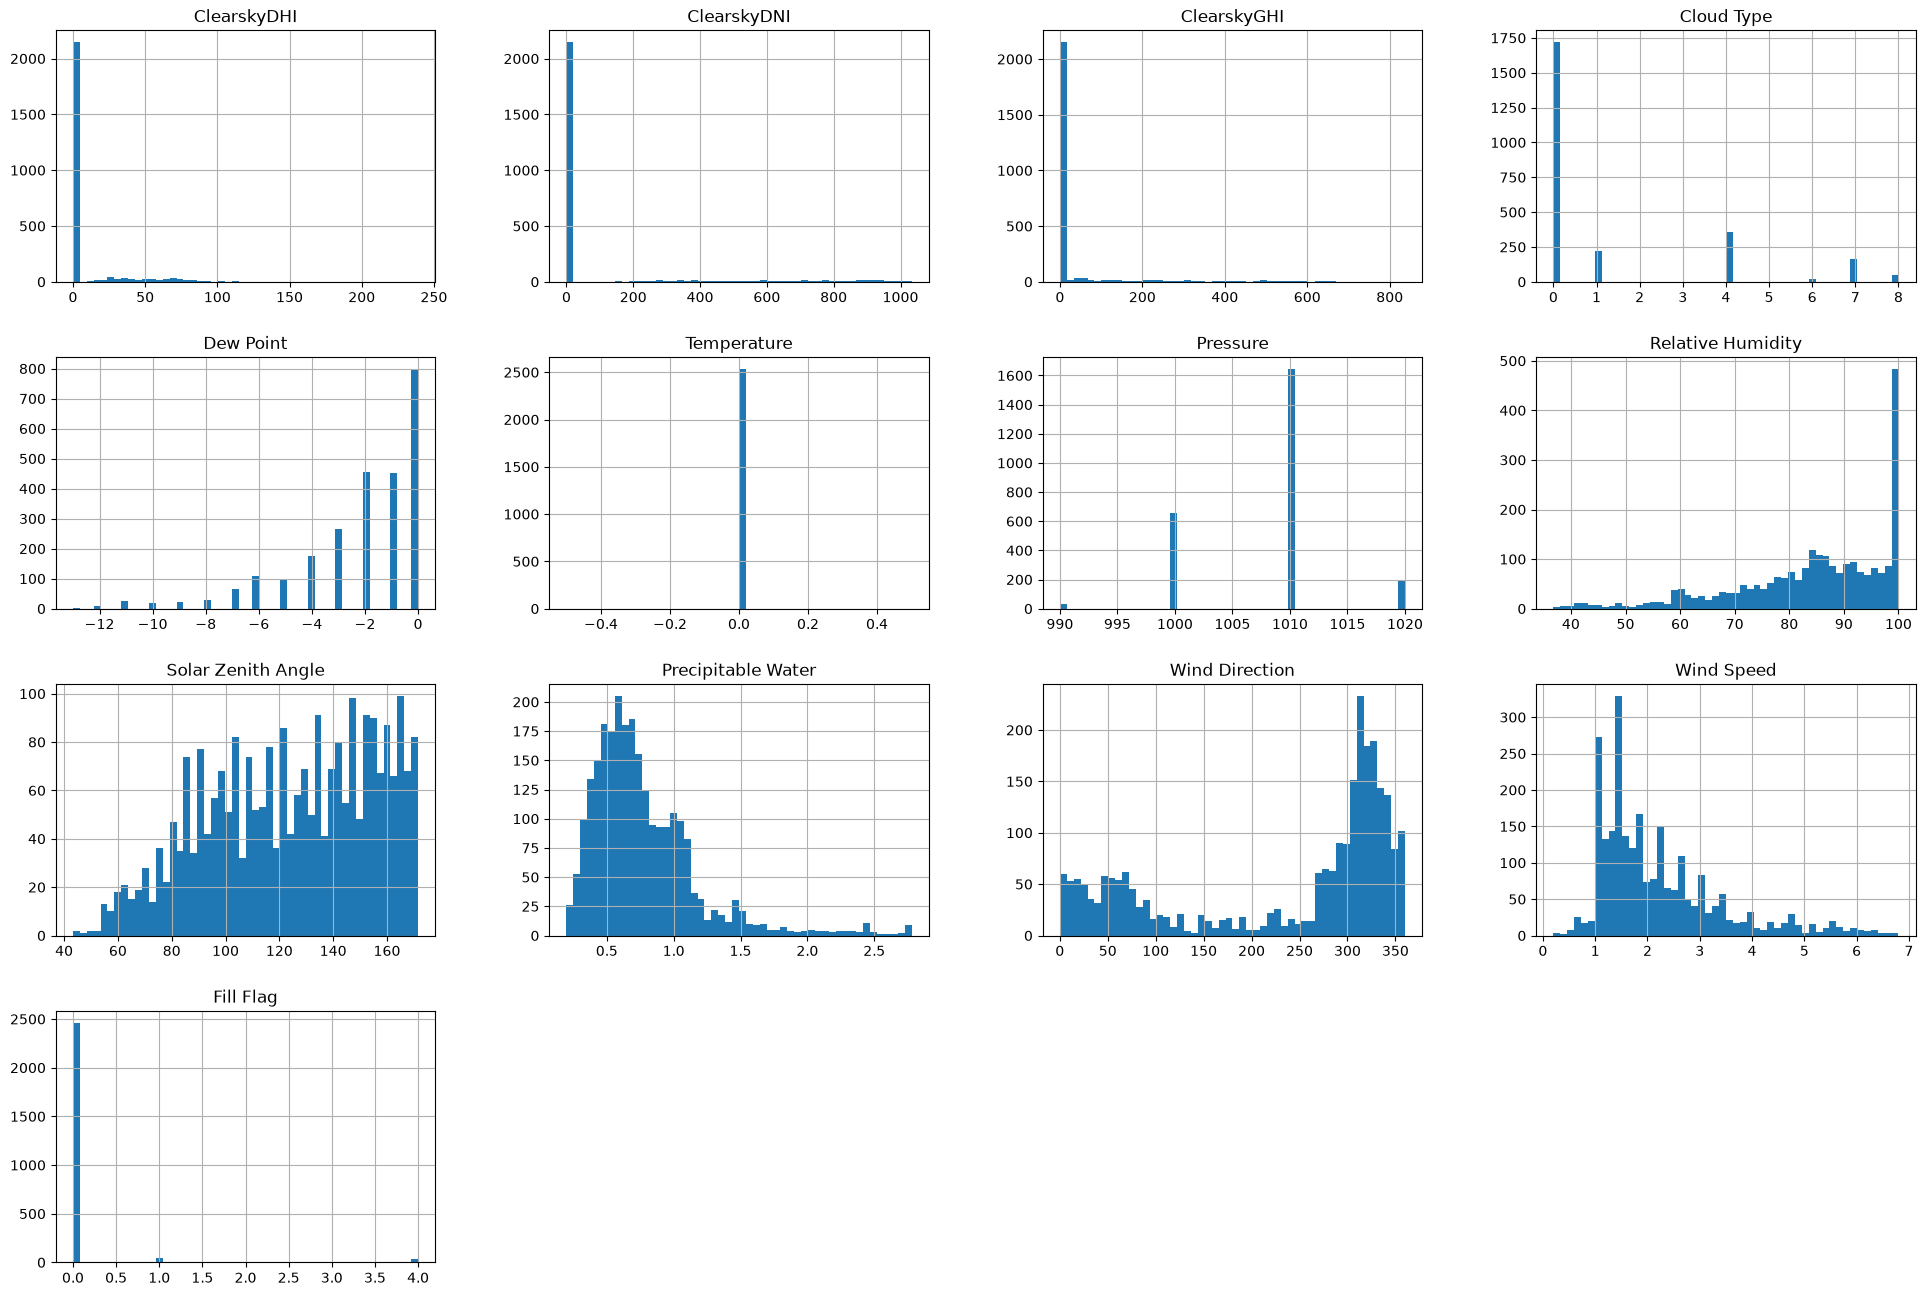

In [11]:
train_raw[train_raw['Temperature'] == 0].hist(figsize = (24, 16), bins=50)
plt.show()

In [12]:
train_raw['Temperature'].value_counts().sort_index().loc[-3:3]

Temperature
-3     560
-2     613
-1     900
 0    2532
 1    1659
 2    1838
 3    2113
Name: count, dtype: int64

In [13]:
mean_zenith = train_raw.groupby(train_raw.index.time)['Solar Zenith Angle'].mean()
mean_zenith

00:00:00     94.856453
00:30:00    101.007943
01:00:00    107.102011
01:30:00    113.101819
02:00:00    118.964932
02:30:00    124.636909
03:00:00    130.046389
03:30:00    135.096237
04:00:00    139.649559
04:30:00    143.503042
05:00:00    146.333852
05:30:00    147.627816
06:00:00    146.946009
06:30:00    144.568491
07:00:00    141.038582
07:30:00    136.722066
08:00:00    131.848245
08:30:00    126.570672
09:00:00    120.997660
09:30:00    115.208524
10:00:00    109.263152
10:30:00    103.208290
11:00:00     97.082340
11:30:00     90.918841
12:00:00     84.748108
12:30:00     78.599373
13:00:00     72.505093
13:30:00     66.500131
14:00:00     60.627557
14:30:00     54.941022
15:00:00     49.510773
15:30:00     44.431664
16:00:00     39.836173
16:30:00     35.919528
17:00:00     32.990313
17:30:00     31.567813
18:00:00     32.192279
18:30:00     34.613940
19:00:00     38.217688
19:30:00     42.606562
20:00:00     47.543666
20:30:00     52.874128
21:00:00     58.490307
21:30:00   

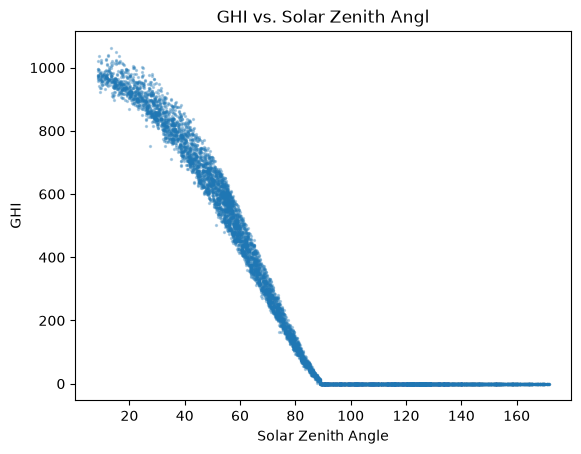

In [14]:
plot_sample = train_raw.sample(10000, random_state = 42)
plt.scatter(plot_sample['Solar Zenith Angle'], plot_sample['ClearskyGHI'], s=2, alpha=0.3)
plt.title('GHI vs. Solar Zenith Angl')
plt.ylabel('GHI')
plt.xlabel('Solar Zenith Angle')
plt.show()

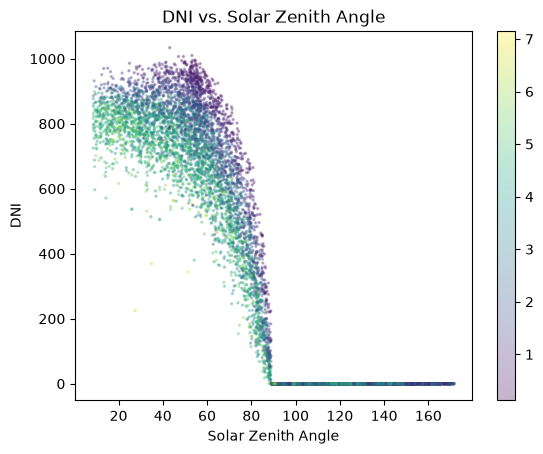

In [ ]:
plt.scatter(plot_sample['Solar Zenith Angle'], plot_sample['ClearskyDNI'], c=plot_sample['Precipitable Water'], cmap="viridis", s=2, alpha=0.3)
plt.title('DNI vs. Solar Zenith Angle')
plt.ylabel('DNI')
plt.xlabel('Solar Zenith Angle')
plt.colorbar()
plt.show()

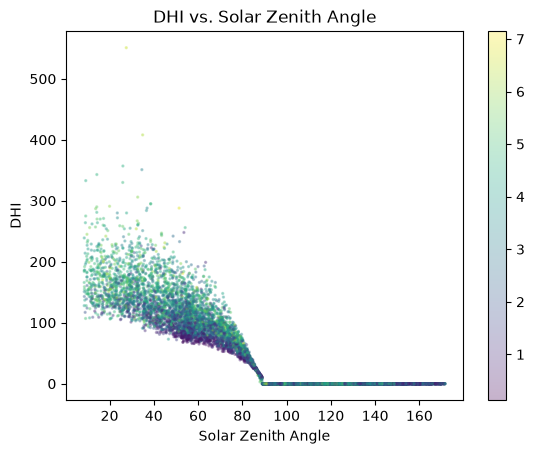

In [ ]:
plt.scatter(plot_sample['Solar Zenith Angle'], plot_sample['ClearskyDHI'], c=plot_sample['Precipitable Water'], cmap="viridis", s=2, alpha=0.3)
plt.title('DHI vs. Solar Zenith Angle')
plt.ylabel('DHI')
plt.xlabel('Solar Zenith Angle')
plt.colorbar()
plt.show()

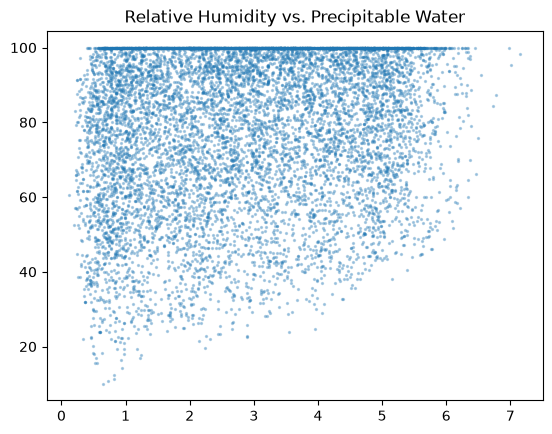

In [17]:
plt.scatter(plot_sample['Precipitable Water'], plot_sample['Relative Humidity'], s=2, alpha=0.3)
plt.title('Relative Humidity vs. Precipitable Water')
plt.show()

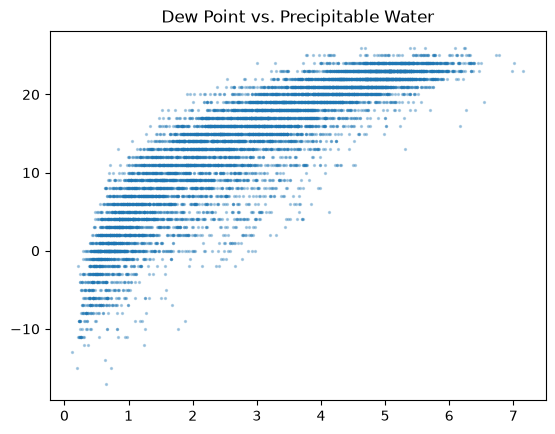

In [18]:
plt.scatter(plot_sample['Precipitable Water'], plot_sample['Dew Point'], s=2, alpha=0.3)
plt.title('Dew Point vs. Precipitable Water')
plt.show()

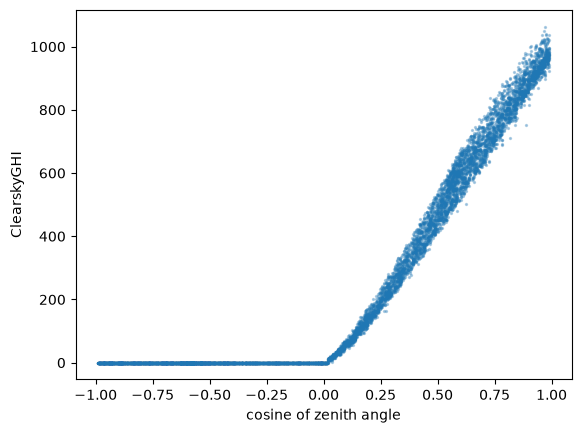

In [30]:
import numpy as np

plot_sample['cosine_zenith'] = np.cos(np.radians(plot_sample['Solar Zenith Angle']))


plt.scatter(plot_sample['cosine_zenith'], plot_sample['ClearskyGHI'], s=2, alpha=0.3)
plt.xlabel('cosine of zenith angle')
plt.ylabel('ClearskyGHI')
plt.show()

In [19]:
train_raw.groupby(train_raw.index.year)[['ClearskyGHI', 'ClearskyDNI', 'ClearskyDHI']].mean()

,ClearskyGHI,ClearskyDNI,ClearskyDHI
2009,253.753938,325.143322,55.028082
2010,255.137329,330.447260,54.099715
2011,253.696347,320.293893,57.966324
2012,253.863730,328.909495,52.852288
2013,253.931564,328.705023,52.963356
2014,254.552683,330.267979,53.089384
2015,253.261872,328.754224,52.521632
2016,255.669684,337.939151,50.001082
2017,253.989441,329.283162,52.605080


In [20]:
train_raw.groupby(train_raw.index.month)[['ClearskyGHI', 'ClearskyDNI', 'ClearskyDHI']].mean()

,ClearskyGHI,ClearskyDNI,ClearskyDHI
1,166.696087,301.115367,31.691906
2,208.707267,316.147966,42.240240
3,259.164277,326.612903,57.579749
4,305.675617,351.365509,65.629630
5,331.465128,365.929286,70.017996
6,335.595756,361.265586,73.895602
7,326.561305,348.737978,74.465352
8,302.663008,336.109543,67.813247
9,265.693596,328.085880,55.203858
10,221.633065,329.708483,39.135603


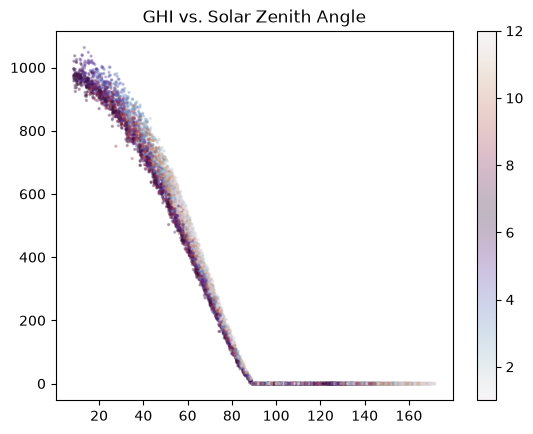

In [21]:
plt.scatter(plot_sample['Solar Zenith Angle'], plot_sample['ClearskyGHI'], c=plot_sample.index.month, s=2, alpha=0.3, cmap='twilight')
plt.title('GHI vs. Solar Zenith Angle')
plt.colorbar()
plt.show()